# Полезный эффект новостей: овернайт → $|r|$ XLK сверх VIX

S&P close-to-close **не** место, где NYT добавляет к VIX (это уже было). Эффект есть в другом окне и на другом активе:

* новости **после закрытия $t-1$ и до 9:30 ET дня $t$** (известны к открытию — можно торговать);
* цель — $\log(|r_t|+\epsilon)$ **XLK** (технологический ETF): у VIX слабая власть над idio-волой теха, у заголовков — есть.

$$
x_t = A^{\Delta t} x_{t-1}+\varepsilon_t^{\mathrm{ovn}},\qquad
\hat y_t = g_0+\langle g,x_t\rangle,\qquad y_t=\log(|r^{\mathrm{XLK}}_t|+\epsilon).
$$

Главная проверка: HAR+лаг VIX vs HAR+VIX+$x_t$, тест Кларка–Веста. Train с 2008 (цифровые timestamps; до этого NYT часто без часа).

In [1]:
TRAIN_START = "2008-01-01"   # до этого timestamps часто полночь
TRAIN_END = "2016-12-31"
VAL_END = "2019-12-31"
TARGET = "XLK"
TARGET_KIND = "logabs"
INCLUDE_TODAY = True         # ε_t овернайт входит в x_t
A_KIND = "diag"
RIDGES = (1e-2, 1e-1, 1.0)
PANEL = [
    ("XLK", "logabs"), ("^GSPC", "logabs"), ("XLF", "logabs"), ("XLE", "logabs"),
    ("CL=F", "logabs"), ("XLK", "logret"), ("^GSPC", "logret"),
]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scripts.build_dataset import ensure_dataset
from scripts import align as A
from scripts import embed as E
from scripts import ou as OU

paths = ensure_dataset()
daily = pd.read_parquet(paths["daily"])
wide = pd.read_parquet(paths["prices_wide"])
daily["date"] = pd.to_datetime(daily["date"])
dates = pd.DatetimeIndex(daily["date"])
wide = wide.reindex(dates)
dt = OU.calendar_dt(dates)

masks = OU.split_masks(dates, TRAIN_END, VAL_END)
train0 = np.asarray(dates >= TRAIN_START) & masks["train"]
masks = {**masks, "train": train0}
tv = masks["train"] | masks["val"]
test = masks["test"]

news = pd.read_parquet(paths["news"], columns=[
    "pub_time_utc", "trading_date", "is_finance", "headline", "abstract", "lead_paragraph",
])
news["trading_date"] = pd.to_datetime(news["trading_date"])
on_text = A.ensure_overnight_texts(news, dates)
dummy = daily.copy()
dummy["n_finance"] = (on_text.str.len() > 0).astype(int)

y = OU.target(wide, TARGET, TARGET_KIND)
r_spx = OU.target(wide, "^GSPC", "logret")
vix = wide["^VIX"].astype(float).to_numpy()
vlag = np.concatenate([[np.nan], vix[:-1]])
Y_panel, panel_names = OU.target_panel(wide, PANEL)

print(f"overnight → {TARGET} {TARGET_KIND}, train {dates[masks['train']][0].date()} → {dates[masks['train']][-1].date()} n={int(masks['train'].sum())}")
print(f"empty overnight days {int((on_text.str.len()==0).sum())}")


12:39:41 INFO scripts.build_dataset: dataset found in C:\Users\mperi\news-embed-for-finance-prediction\data\processed - reusing (pass force=True to rebuild)


overnight → XLK logabs, train 2008-01-02 → 2016-12-30 n=2267
empty overnight days 0


In [3]:
eps, feat_names, _ = E.build_news_features(
    dummy, on_text, masks["train"],
    use_sbert=False, use_topics=True, count_from_text=True, dates=dates,
)
print("ε", eps.shape, feat_names)


ε (6539, 8) ['log_len', 'neg_share', 'polarity', 'log_n_lines', 'energy', 'fed', 'banks', 'novelty']


In [4]:
# HAR+VIX  vs  HAR+VIX+x_t  (x_t = EWMA овернайта, λ=0.8, известен к 9:30)
scored = OU.score_news(
    eps, y, dt, masks["train"], test,
    lam=0.8, include_today=INCLUDE_TODAY, ridge=0.1, controls=vlag,
)
cw = scored["nested"]["clark_west"]
print("restricted  HAR+VIX      test R²={r2:.4f}  IC={ic:.4f}".format(**scored["nested"]["restricted"]))
print("unrestricted HAR+VIX+x   test R²={r2:.4f}  IC={ic:.4f}".format(**scored["nested"]["unrestricted"]))
print(f"Clark–West t={cw['t']:.2f}  p={cw['p']:.2e}   (H0: новости не добавляют)")
print("news-only                 test R²={r2:.4f}  IC={ic:.4f}".format(**scored["news"]))


restricted  HAR+VIX      test R²=0.0018  IC=0.2997
unrestricted HAR+VIX+x   test R²=0.0547  IC=0.3040
Clark–West t=7.94  p=1.01e-15   (H0: новости не добавляют)
news-only                 test R²=-0.1028  IC=0.1731


In [5]:
# диагональная A переобучается и съедает вложенный эффект; ниже — для сравнения. Рабочая модель — EWMA λ=0.8 выше.
picked = OU.select_ridge(
    eps, y, dt, masks["train"], masks["val"], kind=A_KIND, ridges=RIDGES, include_today=INCLUDE_TODAY,
)
best = OU.fit_dynamics(
    eps, y, dt, tv, test, kind=A_KIND, ridge=picked["ridge"], include_today=INCLUDE_TODAY,
)
best["test"] = OU.metrics(y[test], best["yhat"][test])
print(f"A=diag ridge={picked['ridge']} valR²={picked['val']['r2']:.4f}  "
      f"testR²={best['test']['r2']:.4f} IC={best['test']['ic']:.4f}")
print("half-life (days)", np.round(best["half_life"], 2))

# вложенная модель уже с выученным x
nested = OU.nested_news(y, best["x"], masks["train"], test, controls=vlag, ridge=0.1)
print("after fitted A: rest R²={r2:.4f}".format(**nested["restricted"]),
      "unres R²={r2:.4f}".format(**nested["unrestricted"]),
      f"CW t={nested['clark_west']['t']:.2f} p={nested['clark_west']['p']:.2e}")
hac = OU.ic_hac(y[test], best["yhat"][test])
lo, hi = OU.block_bootstrap_ic(y[test], best["yhat"][test])
print(f"news-only IC HAC t={hac['t_hac']:.2f} p={hac['p_hac']:.3f}  bootstrap 95% [{lo:.3f},{hi:.3f}]")


A=diag ridge=0.01 valR²=0.0090  testR²=-0.0365 IC=0.1410
half-life (days) [ 0.79 17.66  1.27  1.08  1.07  1.    0.97  0.99]
after fitted A: rest R²=0.0018 unres R²=-0.0104 CW t=0.09 p=4.63e-01
news-only IC HAC t=4.52 p=0.000  bootstrap 95% [0.087,0.194]


In [6]:
# те же овернайт-признаки, разные цели (скоринг λ=0.8, вложенность vs HAR+VIX)
rows = []
for i, name in enumerate(panel_names):
    rec = OU.score_news(
        eps, Y_panel[:, i], dt, masks["train"], test,
        lam=0.8, include_today=True, ridge=0.1, controls=vlag,
    )
    rows.append({
        "target": name,
        "news IC": rec["news"]["ic"],
        "HAR+VIX R²": rec["nested"]["restricted"]["r2"],
        "HAR+VIX+x R²": rec["nested"]["unrestricted"]["r2"],
        "CW t": rec["nested"]["clark_west"]["t"],
        "CW p": rec["nested"]["clark_west"]["p"],
    })
pd.DataFrame(rows).round(4)


,target,news IC,HAR+VIX R²,HAR+VIX+x R²,CW t,CW p
0,XLK logabs,0.1731,0.0018,0.0547,7.9401,0.0000
1,^GSPC logabs,0.1571,0.1529,0.1527,4.6809,0.0000
2,XLF logabs,0.1170,0.1398,0.1142,1.3360,0.0908
3,XLE logabs,0.0524,0.0878,0.0669,1.8561,0.0317
4,CL=F logabs,0.1300,0.0553,0.0310,2.6591,0.0039
5,XLK logret,0.0103,0.0169,0.0101,1.0302,0.1514
6,^GSPC logret,0.0062,0.0185,0.0026,1.4499,0.0735


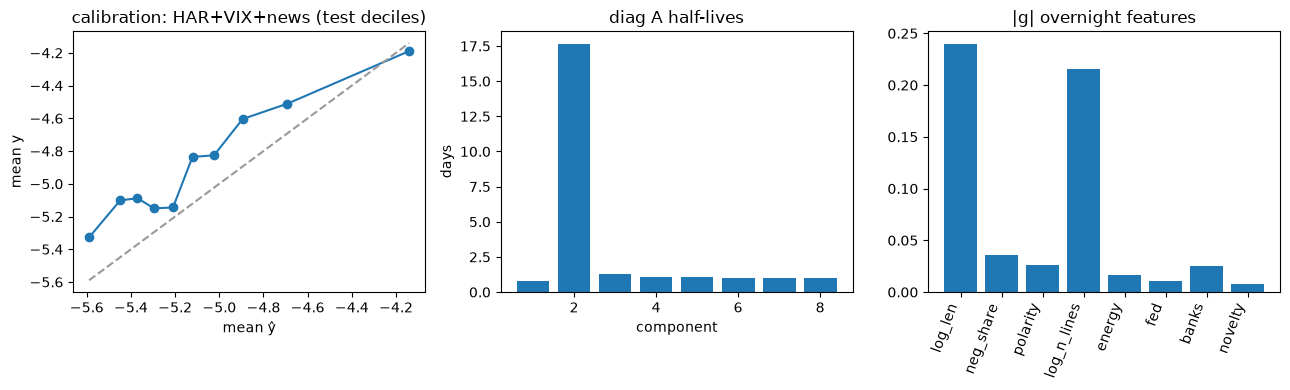

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
cal = OU.calibration_deciles(y[test], scored["nested"]["yhat_u"][test])
ax[0].plot(cal["yhat"], cal["y"], marker="o")
lim = [min(cal.yhat.min(), cal.y.min()), max(cal.yhat.max(), cal.y.max())]
ax[0].plot(lim, lim, color="0.6", ls="--")
ax[0].set_title("calibration: HAR+VIX+news (test deciles)")
ax[0].set_xlabel("mean ŷ"); ax[0].set_ylabel("mean y")

hl = np.asarray(best["half_life"])
ax[1].bar(np.arange(1, len(hl)+1), np.where(np.isfinite(hl), hl, 0))
ax[1].set_title("diag A half-lives")
ax[1].set_xlabel("component"); ax[1].set_ylabel("days")

g = np.asarray(best["g"]).ravel()
ax[2].bar(np.arange(len(feat_names)), np.abs(g[:len(feat_names)]))
ax[2].set_xticks(np.arange(len(feat_names)), feat_names, rotation=70, ha="right")
ax[2].set_title("|g| overnight features")
plt.tight_layout()


Почему это не тот же провал, что на S&P: VIX — implied vol рынка, он уже почти исчерпывает $|r|$ индекса. У XLK остаётся idio-вола (FAANG/техноновости ночью). Окно до 9:30 — единственное next-session окно без подглядывания в дневную ленту.

Знак доходности по-прежнему почти не берётся. Калиман не нужен: $\varepsilon_t$ наблюдаем.